In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pysam
import subprocess

In [2]:
sorted_bam = "../results/02_alignment/aligned.sorted.bam"
markdup_metrics_file = "../results/03_mark_duplicates/marked_duplicates_metrics.txt"

In [3]:
def run_command(cmd):
    result = subprocess.run(
        cmd,
        shell=True,
        capture_output=True,
        text=True
    )
    return result.stdout.strip()

In [4]:
#  FLAGSTAT 

flagstat = run_command(f"samtools flagstat {sorted_bam}")
print(flagstat)

# parsiranje kljucnih vrednosti
total_reads = None
mapped_reads = None
properly_paired = None

for line in flagstat.splitlines():
    if "in total" in line:
        total_reads = int(line.split()[0])
    elif "mapped (" in line and "primary mapped" not in line:
        mapped_reads = int(line.split()[0])
    elif "properly paired" in line:
        properly_paired = int(line.split()[0])

print(f"\nUkupan broj readova:              {total_reads}")
print(f"Broj mapiranih readova:           {mapped_reads}")
print(f"Broj properly paired readova:     {properly_paired}")
print(f"Procenat mapiranih:               {mapped_reads/total_reads*100:.2f}%")
print(f"Procenat properly paired:         {properly_paired/total_reads*100:.2f}%")

6065505 + 0 in total (QC-passed reads + QC-failed reads)
6060318 + 0 primary
0 + 0 secondary
5187 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
5476332 + 0 mapped (90.29% : N/A)
5471145 + 0 primary mapped (90.28% : N/A)
6060318 + 0 paired in sequencing
3030159 + 0 read1
3030159 + 0 read2
5396810 + 0 properly paired (89.05% : N/A)
5447214 + 0 with itself and mate mapped
23931 + 0 singletons (0.39% : N/A)
20764 + 0 with mate mapped to a different chr
16001 + 0 with mate mapped to a different chr (mapQ>=5)

Ukupan broj readova:              6065505
Broj mapiranih readova:           5476332
Broj properly paired readova:     5396810
Procenat mapiranih:               90.29%
Procenat properly paired:         88.98%


In [5]:
#  MARK DUPLICATES METRIKE 

metrics_df = pd.read_csv(
    markdup_metrics_file,
    sep="\t",
    comment="#",
    nrows=1
)

percent_dup = metrics_df["PERCENT_DUPLICATION"].values[0] * 100
estimated_library_size = metrics_df["ESTIMATED_LIBRARY_SIZE"].values[0]

print(f"Procenat duplikata:               {percent_dup:.2f}%")
print(f"Procenjena velicina biblioteke:   {estimated_library_size}")

Procenat duplikata:               3.48%
Procenjena velicina biblioteke:   40595399


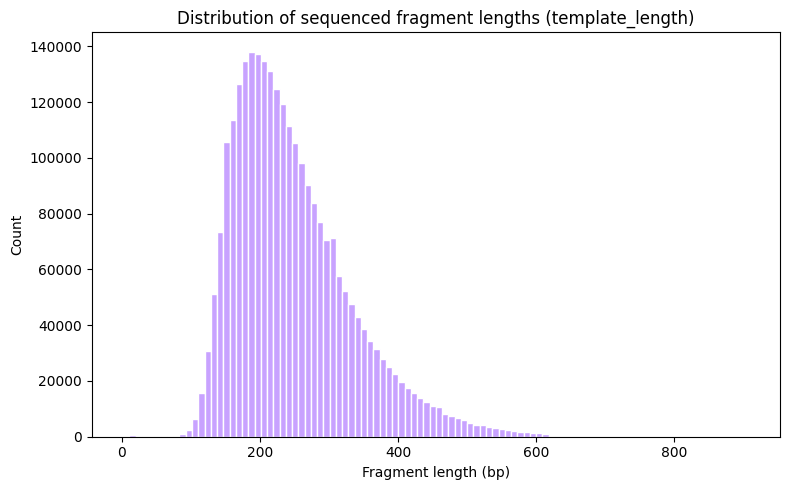

Broj fragmenata u histogramu: 2698964


In [ ]:
#  HISTOGRAM DUZINA FRAGMENATA

bam = pysam.AlignmentFile(sorted_bam)

lengths = [
    abs(read.template_length)
    for read in bam
    if read.is_proper_pair
    and read.template_length > 0
    and abs(read.template_length) < 1000
]

bam.close()

plt.figure(figsize=(8, 5))
plt.hist(lengths, bins=100, color="#C8A2FF", edgecolor="white")
plt.xlabel("Fragment length (bp)")
plt.ylabel("Count")
plt.title("Distribution of sequenced fragment lengths (template_length)")
plt.tight_layout()
#plt.savefig("fragment_length_histogram.png", dpi=300)
plt.show()

print(f"Broj fragmenata u histogramu: {len(lengths)}")
